
  2 estrategias, con puntaje   N = 100   (100 cadenas, d = 1..100)
  Puntos con M(d) = 0 eliminados: 0
  Puntos usados en el ajuste:     100
  Pendiente:                      -0.4437
  R^2:                            0.5322
  Guardado: resultados_fase3_loglog\loglog_Md_con_puntaje_N100.png


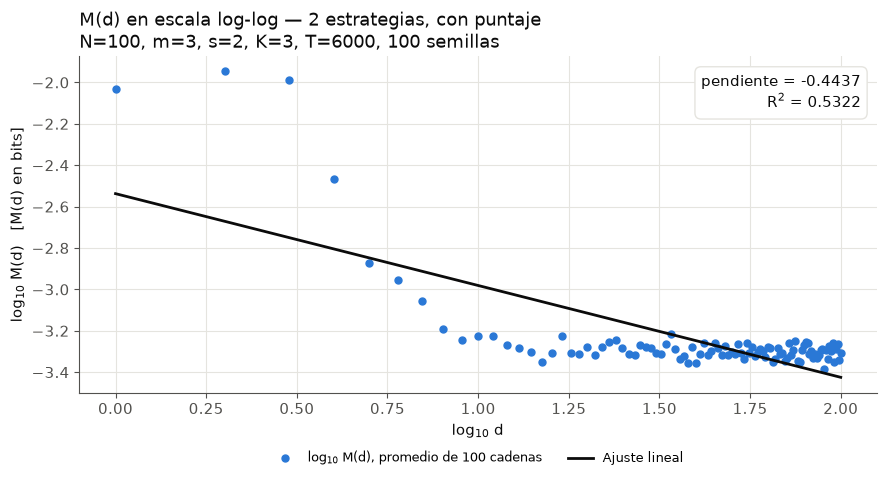


  2 estrategias, con puntaje   N = 125   (100 cadenas, d = 1..100)
  Puntos con M(d) = 0 eliminados: 0
  Puntos usados en el ajuste:     100
  Pendiente:                      -0.3608
  R^2:                            0.5544
  Guardado: resultados_fase3_loglog\loglog_Md_con_puntaje_N125.png


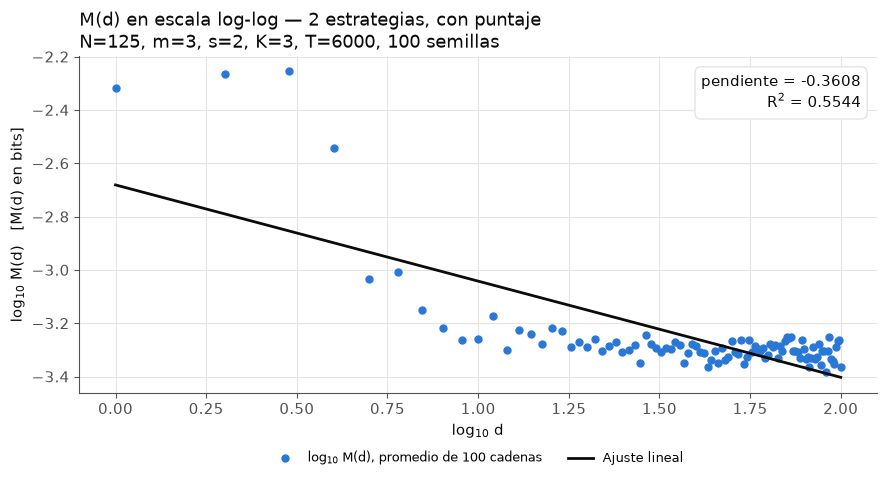


  2 estrategias, con puntaje   N = 151   (100 cadenas, d = 1..100)
  Puntos con M(d) = 0 eliminados: 0
  Puntos usados en el ajuste:     100
  Pendiente:                      -0.2204
  R^2:                            0.5087
  Guardado: resultados_fase3_loglog\loglog_Md_con_puntaje_N151.png


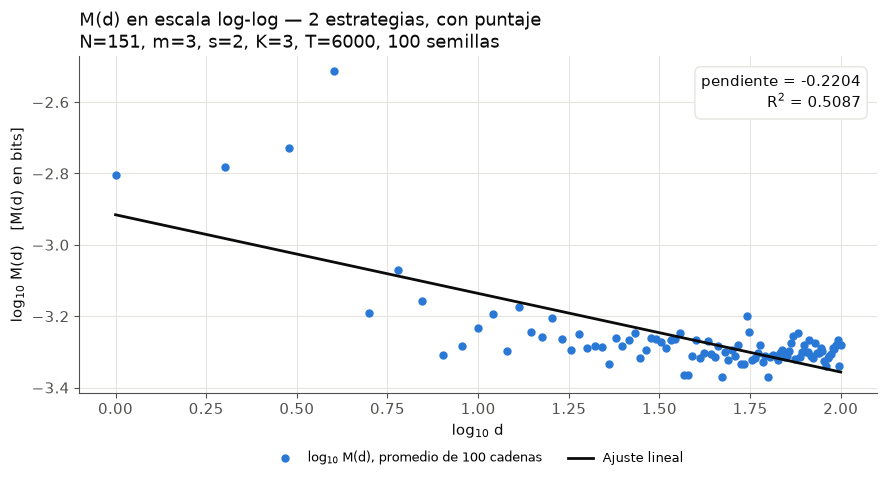


  2 estrategias, con puntaje   N = 175   (100 cadenas, d = 1..100)
  Puntos con M(d) = 0 eliminados: 0
  Puntos usados en el ajuste:     100
  Pendiente:                      -0.0755
  R^2:                            0.1011
  Guardado: resultados_fase3_loglog\loglog_Md_con_puntaje_N175.png


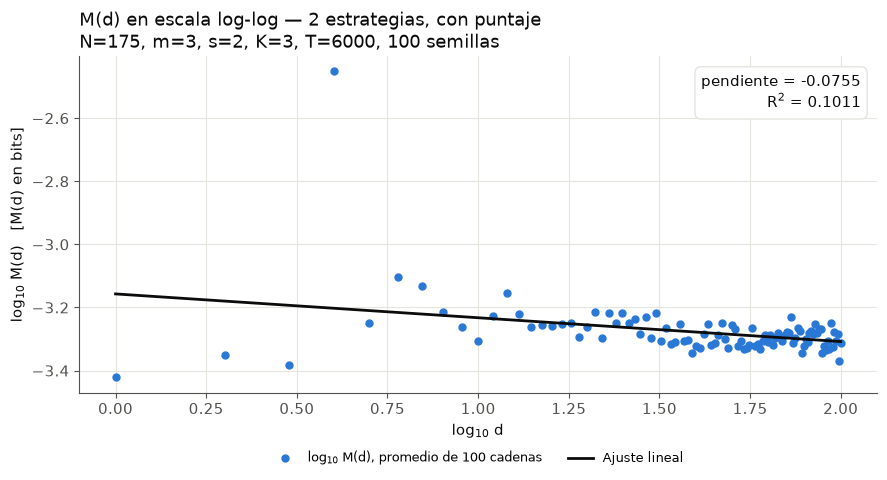


  2 estrategias, con puntaje   N = 200   (100 cadenas, d = 1..100)
  Puntos con M(d) = 0 eliminados: 0
  Puntos usados en el ajuste:     100
  Pendiente:                      0.0320
  R^2:                            0.0078
  Guardado: resultados_fase3_loglog\loglog_Md_con_puntaje_N200.png


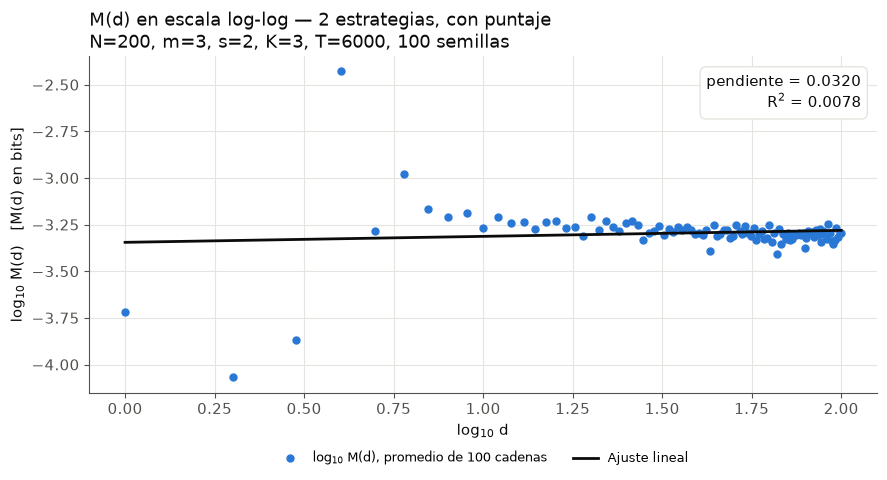


  RESUMEN  (2 estrategias, con puntaje, m=3, T=6000)
       N  pendiente      R^2
     100    -0.4437   0.5322
     125    -0.3608   0.5544
     151    -0.2204   0.5087
     175    -0.0755   0.1011
     200     0.0320   0.0078

  Guardado: resultados_fase3_loglog\ajustes_loglog_con_puntaje.csv


In [1]:
"""
FASE 3 (aumento de N): M(d) en escala log-log
==============================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion

Que hace este codigo
--------------------
NO vuelve a simular. Lee los CSV "todas_las_cadenas" que genero el codigo
Paso_3 (2 estrategias CON puntaje, m = 3, K = 3, T = 6000, 100 semillas)
y, para cada N de la lista N_A_ANALIZAR:

  1. Promedia M(d) sobre las 100 cadenas, para d = 1, ..., 100
     (es la misma curva promedio que se grafico en el Paso 3).
  2. Quita los puntos con M(d) = 0, porque log(0) no existe.
     (Es el UNICO filtro, por indicacion del Dr. Mansilla.)
  3. Calcula log10(d) y log10(M(d)).
  4. Ajusta una recta por minimos cuadrados con TODOS los puntos que quedan:
         log10 M(d) = b + pendiente * log10(d)
     Si M(d) = A / d^alpha, entonces pendiente = -alpha y b = log10(A).
  5. Reporta la PENDIENTE y la R^2 del ajuste.
  6. Grafica log10 M(d) contra log10 d con la recta ajustada.

Es el mismo procedimiento y el mismo formato de grafica que el de la
fase 2 (Fase4_paso2_loglog_tres_casos).

Notacion: gamma = 3^m / N es el parametro de control (no va en el titulo
de las graficas; se guarda en el CSV). alpha es el exponente de la ley de
potencias M(d) = A / d^alpha.
"""

import os
import numpy as np
import matplotlib.pyplot as plt


# =====================================================================
# OPCIONES  <-- AQUI SE DECIDE SI SE GUARDAN LOS ARCHIVOS
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
# True  = ademas se guardan como PNG en la carpeta CARPETA_SALIDA
# False = solo se muestran, no se guarda ningun PNG
DESCARGAR_GRAFICAS = True

# True  = se guarda un CSV con la pendiente y la R^2 de cada N
GUARDAR_CSV        = True

CARPETA_SALIDA = "resultados_fase3_loglog"


# =====================================================================
# QUE N SE ANALIZAN  <-- para agregar otro N, solo agregalo a la lista
# =====================================================================
# Cada N necesita su archivo Paso3_Md_con_puntaje_N<N>_todas_las_cadenas.csv
# en la misma carpeta que este notebook.
N_A_ANALIZAR = [100,125,151,175,200]

ETIQUETA = "con_puntaje"
DESCRIPCION = "2 estrategias, con puntaje"

M, S, K, T, N_CADENAS = 3, 2, 3, 6000, 100


# =====================================================================
# LECTURA Y PROMEDIO
# =====================================================================
def leer_promedio(archivo):
    """Lee el CSV de todas las cadenas y devuelve d y el promedio de M(d).

    Formato del CSV: lineas de encabezado que empiezan con '#';
    despues, una fila por semilla: semilla, M(d=1), ..., M(d=100).
    """
    tabla = np.loadtxt(archivo, delimiter=",", comments="#")
    valores = tabla[:, 1:]                        # se quita la columna semilla
    distancias = np.arange(1, valores.shape[1] + 1)
    return distancias, valores.mean(axis=0), valores.shape[0]


# =====================================================================
# AJUSTE LINEAL EN ESCALA LOG-LOG  (igual que en la fase 2)
# =====================================================================
def ajuste_loglog(d, Md):
    """Quita los ceros, pasa a log10 y ajusta una recta.

    Devuelve un diccionario con la pendiente, la ordenada al origen,
    la R^2, los puntos usados y cuantos ceros se quitaron.
    """
    validos = Md > 0                      # UNICO filtro: fuera M(d) = 0
    x = np.log10(d[validos])
    y = np.log10(Md[validos])

    pendiente, ordenada = np.polyfit(x, y, 1)   # recta y = ordenada + pendiente x
    y_ajuste = ordenada + pendiente * x

    ss_res = np.sum((y - y_ajuste) ** 2)        # suma de cuadrados residual
    ss_tot = np.sum((y - y.mean()) ** 2)        # suma de cuadrados total
    r2 = 1 - ss_res / ss_tot

    return {
        "pendiente": pendiente,
        "ordenada": ordenada,
        "r2": r2,
        "x": x, "y": y, "y_ajuste": y_ajuste,
        "n_puntos": int(validos.sum()),
        "n_ceros": int((~validos).sum()),
    }


# =====================================================================
# GRAFICA  (mismo formato que en la fase 2)
# =====================================================================
AZUL = "#2a78d6"
GRIS = "#52514e"
TINTA = "#0b0b0b"
REJILLA = "#e5e4df"

plt.rcParams.update({
    "font.size": 11,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def graficar(N, res, guardar):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(res["x"], res["y"], "o", color=AZUL, ms=5,
            label=f"log$_{{10}}$ M(d), promedio de {N_CADENAS} cadenas")
    ax.plot(res["x"], res["y_ajuste"], color=TINTA, lw=2,
            label="Ajuste lineal")

    # resultados del ajuste dentro de la grafica
    texto = (f"pendiente = {res['pendiente']:.4f}\n"
             f"R$^2$ = {res['r2']:.4f}")
    ax.text(0.98, 0.95, texto, transform=ax.transAxes, ha="right", va="top",
            fontsize=11, color=TINTA,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=REJILLA))

    ax.set_xlabel("log$_{10}$ d")
    ax.set_ylabel("log$_{10}$ M(d)   [M(d) en bits]")
    ax.set_title(f"M(d) en escala log-log — {DESCRIPCION}\n"
                 f"N={N}, m={M}, s={S}, K={K}, T={T}, {N_CADENAS} semillas",
                 loc="left", color=TINTA)
    ax.grid(color=REJILLA, lw=0.8)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14),
              ncol=2, fontsize=9)
    fig.tight_layout()

    if guardar:
        os.makedirs(CARPETA_SALIDA, exist_ok=True)
        ruta = os.path.join(CARPETA_SALIDA, f"loglog_Md_{ETIQUETA}_N{N}.png")
        fig.savefig(ruta, dpi=200)
        print(f"  Guardado: {ruta}")

    plt.show()
    plt.close(fig)


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":

    resumen = []

    for N in N_A_ANALIZAR:
        archivo = f"Paso3_Md_{ETIQUETA}_N{N}_todas_las_cadenas.csv"
        if not os.path.exists(archivo):
            print(f"\n  FALTA el archivo {archivo}; se omite N = {N}.")
            continue

        gamma = K ** M / N
        d, Md, n_cad = leer_promedio(archivo)
        res = ajuste_loglog(d, Md)

        print("\n" + "=" * 62)
        print(f"  {DESCRIPCION}   N = {N}   ({n_cad} cadenas, d = 1..{d[-1]})")
        print("=" * 62)
        print(f"  Puntos con M(d) = 0 eliminados: {res['n_ceros']}")
        print(f"  Puntos usados en el ajuste:     {res['n_puntos']}")
        print(f"  Pendiente:                      {res['pendiente']:.4f}")
        print(f"  R^2:                            {res['r2']:.4f}")

        graficar(N, res, DESCARGAR_GRAFICAS)

        resumen.append([N, gamma, res["n_ceros"], res["n_puntos"],
                        res["pendiente"], res["r2"], res["ordenada"]])

    # --- tabla resumen ---
    print("\n" + "=" * 62)
    print(f"  RESUMEN  ({DESCRIPCION}, m={M}, T={T})")
    print("=" * 62)
    print(f"  {'N':>6s} {'pendiente':>10s} {'R^2':>8s}")
    for N, _, _, _, p, r2, _ in resumen:
        print(f"  {N:>6d} {p:>10.4f} {r2:>8.4f}")

    if GUARDAR_CSV and resumen:
        os.makedirs(CARPETA_SALIDA, exist_ok=True)
        ruta = os.path.join(CARPETA_SALIDA, f"ajustes_loglog_{ETIQUETA}.csv")
        with open(ruta, "w", encoding="utf-8") as f:
            f.write("# Ajuste lineal de log10 M(d) vs log10 d, d = 1..100, "
                    "promedio de 100 cadenas\n")
            f.write(f"# {DESCRIPCION}, m={M} s={S} K={K} T={T}; "
                    "unico filtro: se quitan los M(d) = 0\n")
            f.write("N,gamma,ceros_eliminados,puntos_usados,pendiente,R2,"
                    "ordenada_log10\n")
            for N, g, c, n, p, r2, b in resumen:
                f.write(f"{N},{g:.6f},{c},{n},{p:.6f},{r2:.6f},{b:.6f}\n")
        print(f"\n  Guardado: {ruta}")